# 🪟 SAM Building Segmentation - Fixed Version

**Problem with previous version:** The seed boxes were selecting bright spots, not actual windows.

**Fix:** In thermal images, windows typically appear as:
- **Cooler (purple/blue)** - when showing glass surface temperature
- **Warmer (yellow/bright)** - when showing interior heat through glass

We need to select the actual window rectangles (the dark purple areas on walls).

## 1. Setup

In [1]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git
!pip install -q opencv-python-headless
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from segment_anything import sam_model_registry, SamPredictor
import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"✅ Setup complete! Using: {device}")

  Preparing metadata (setup.py) ... done
✅ Setup complete! Using: cpu


In [2]:
# Load SAM
sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth")
sam.to(device=device)
predictor = SamPredictor(sam)
print("✅ SAM loaded!")

✅ SAM loaded!


## 2. Upload Image

📤 Upload your thermal image:


Saving IRX_2927.JPG to IRX_2927.JPG
📐 Image: 640 x 512


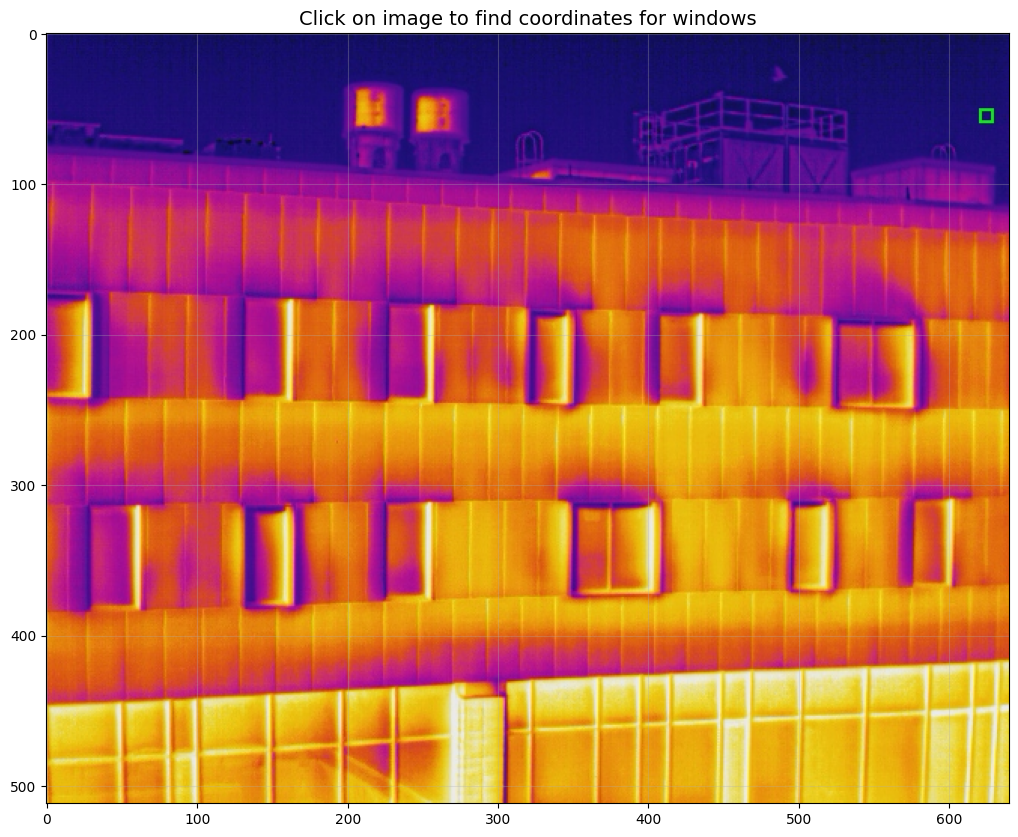

In [3]:
print("📤 Upload your thermal image:")
uploaded = files.upload()
IMAGE_PATH = list(uploaded.keys())[0]

image_bgr = cv2.imread(IMAGE_PATH)
rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
h, w = gray.shape

print(f"📐 Image: {w} x {h}")

# Show with grid to help identify coordinates
fig, ax = plt.subplots(figsize=(14, 10))
ax.imshow(rgb)
ax.set_title('Click on image to find coordinates for windows', fontsize=14)
ax.grid(True, alpha=0.3)
plt.show()

## 3. 🔍 Understand Your Image First

Let's look at the thermal colors to identify what's what.

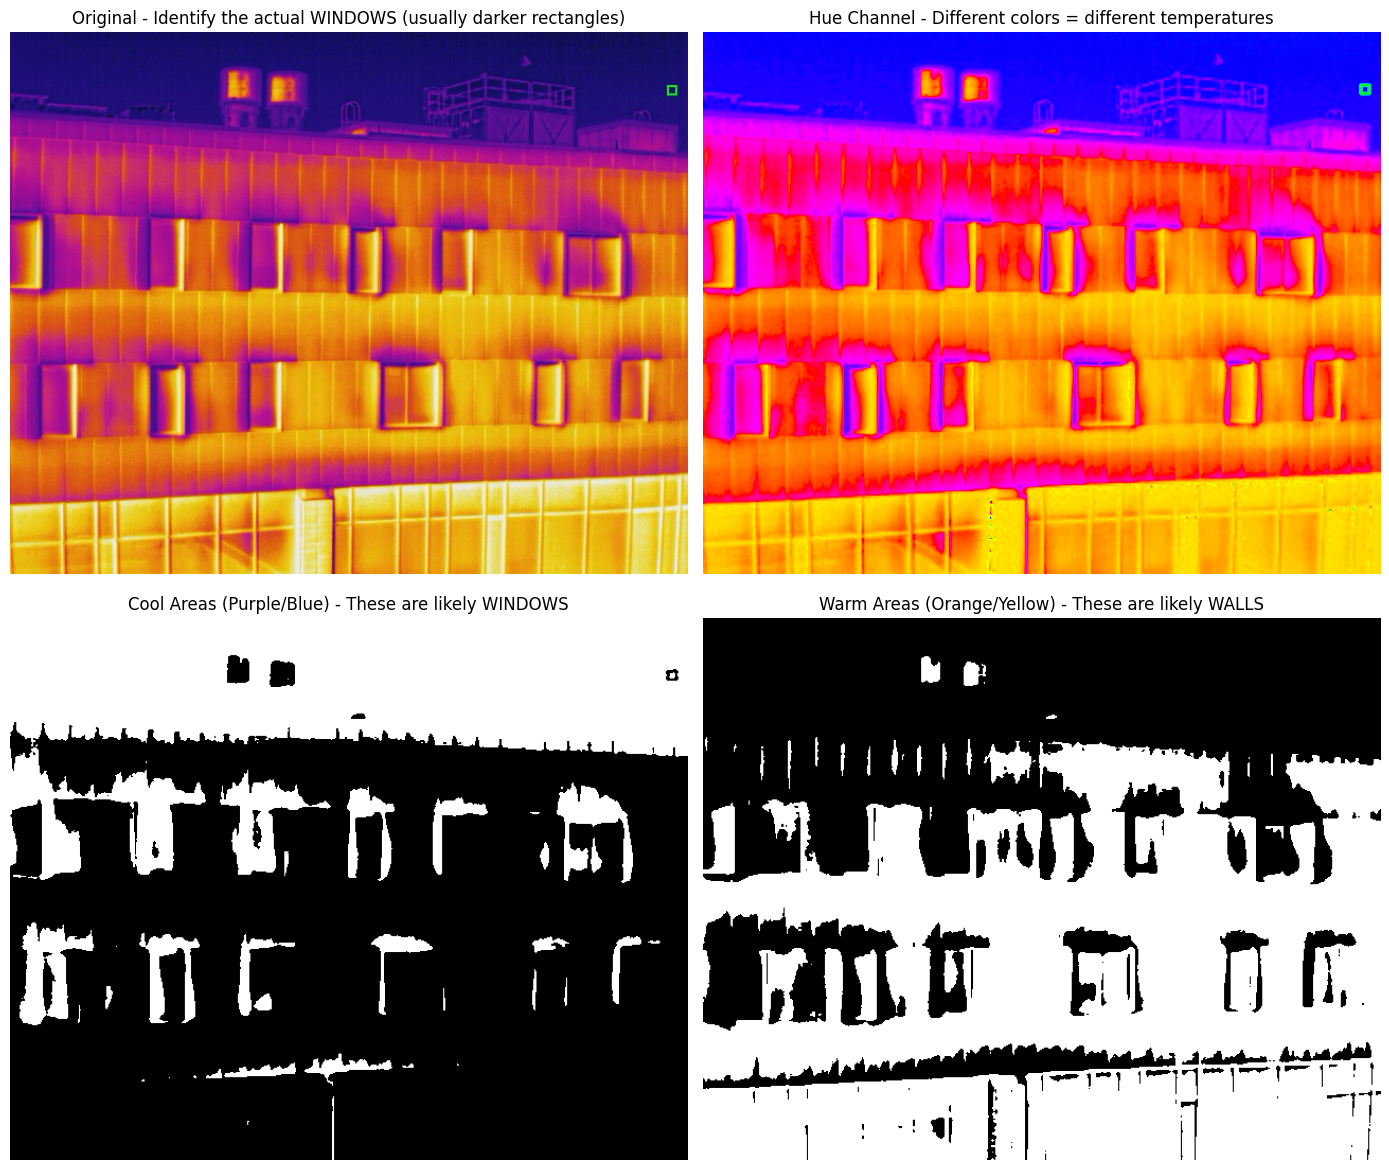


👆 Look at 'Cool Areas' - those purple/blue rectangles are your WINDOWS!
   The orange areas are WALLS, not windows.


In [4]:
# Analyze color distribution
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Original
axes[0, 0].imshow(rgb)
axes[0, 0].set_title('Original - Identify the actual WINDOWS (usually darker rectangles)')
axes[0, 0].axis('off')

# Hue channel (shows temperature zones)
axes[0, 1].imshow(hsv[:,:,0], cmap='hsv')
axes[0, 1].set_title('Hue Channel - Different colors = different temperatures')
axes[0, 1].axis('off')

# Show "cool" areas (likely windows)
# In iron palette: purple/blue = cool, orange/yellow = warm
cool_mask = cv2.inRange(hsv, np.array([100, 30, 30]), np.array([160, 255, 255]))
axes[1, 0].imshow(cool_mask, cmap='gray')
axes[1, 0].set_title('Cool Areas (Purple/Blue) - These are likely WINDOWS')
axes[1, 0].axis('off')

# Show "warm" areas (likely walls)
warm_mask = cv2.inRange(hsv, np.array([5, 50, 100]), np.array([30, 255, 255]))
axes[1, 1].imshow(warm_mask, cmap='gray')
axes[1, 1].set_title('Warm Areas (Orange/Yellow) - These are likely WALLS')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

print("\n👆 Look at 'Cool Areas' - those purple/blue rectangles are your WINDOWS!")
print("   The orange areas are WALLS, not windows.")

## 4. ✏️ Define Window Boxes CORRECTLY

**IMPORTANT:** Select the **dark purple/blue rectangular areas** - those are the actual windows!

Look at the image above and identify 3-5 REAL windows (the cooler rectangular areas).

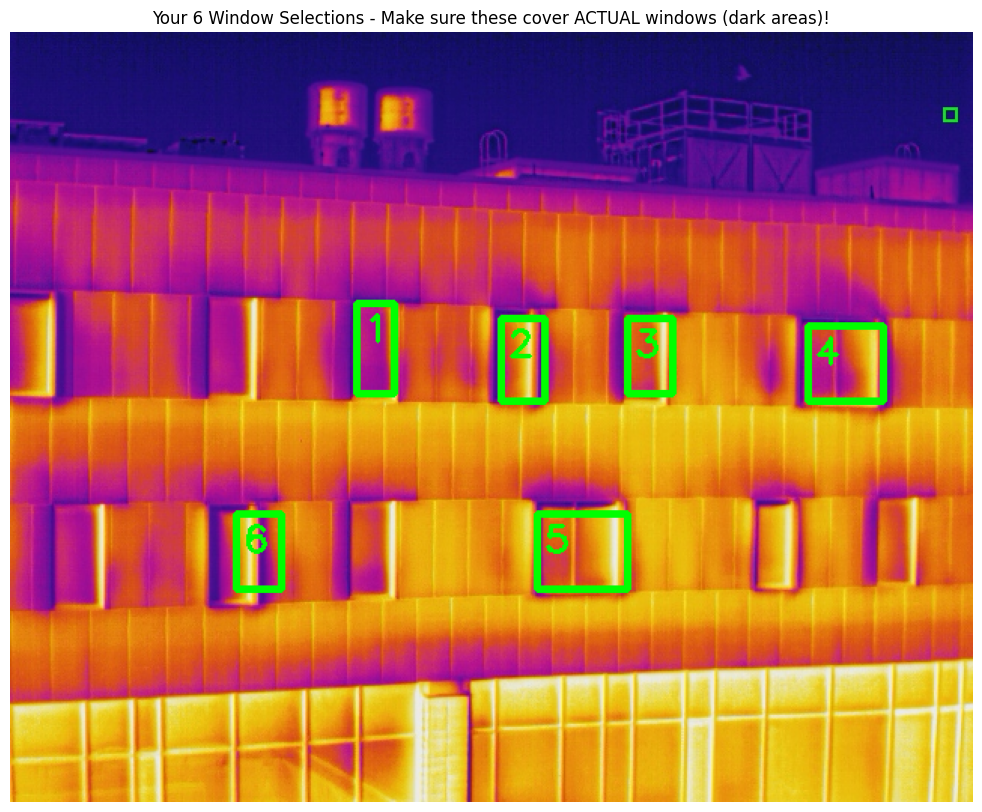


⚠️  CHECK: Are the green boxes around the PURPLE/DARK rectangles (actual windows)?
   If not, edit WINDOW_BOXES above and re-run!


In [22]:
# ============================================
# 👇 DEFINE BOXES AROUND ACTUAL WINDOWS 👇
# These should be the DARK/PURPLE rectangles!
# Format: [x_left, y_top, x_right, y_bottom]
# ============================================

# Example coordinates - YOU MUST ADJUST THESE for your image!
# Look for the purple/blue rectangular window areas

WINDOW_BOXES = [
    # Row 1 windows (upper windows on building)
    [230, 180, 255, 240],   # Window 1
    [326, 190, 355, 245],   # Window 2
    [410, 190, 440, 240],   # Window 3
    [530, 195, 580, 245],   # Third window

    # Row 2 windows (lower windows)
    [350, 320, 410, 370],   # Lower left window
    [130, 320, 180, 370],   # Lower middle window
]

# ============================================

# Preview
vis = rgb.copy()
for i, (x0, y0, x1, y1) in enumerate(WINDOW_BOXES):
    cv2.rectangle(vis, (x0, y0), (x1, y1), (0, 255, 0), 3)
    cv2.putText(vis, str(i+1), (x0+5, y0+25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

plt.figure(figsize=(14, 10))
plt.imshow(vis)
plt.title(f'Your {len(WINDOW_BOXES)} Window Selections - Make sure these cover ACTUAL windows (dark areas)!')
plt.axis('off')
plt.show()

print("\n⚠️  CHECK: Are the green boxes around the PURPLE/DARK rectangles (actual windows)?")
print("   If not, edit WINDOW_BOXES above and re-run!")

## 5. Interactive Box Selection Tool
Use this to help find coordinates.

In [ ]:
# Helper: Click on image to get coordinates
from google.colab import output

fig, ax = plt.subplots(figsize=(14, 10))
ax.imshow(rgb)
ax.set_title('Hover/Click to see coordinates (shown in toolbar below)')

# Add coordinate display
def format_coord(x, y):
    return f'x={int(x)}, y={int(y)}'
ax.format_coord = format_coord

plt.show()

print("\n📍 Hover over the image corners of windows to get coordinates.")
print("   Format: [x_left, y_top, x_right, y_bottom]")
print("\n   Example: If a window goes from (155,340) to (230,430):")
print("   Add: [155, 340, 230, 430]")

## 6. Segment Windows with SAM

In [ ]:
# Set image for SAM
predictor.set_image(rgb)

# Segment each window box
window_masks = []

print("Segmenting windows with SAM...")
for i, box in enumerate(WINDOW_BOXES):
    box_array = np.array(box)

    masks, scores, _ = predictor.predict(
        point_coords=None,
        point_labels=None,
        box=box_array[None, :],
        multimask_output=True
    )

    # Get best mask
    best_idx = np.argmax(scores)
    best_mask = masks[best_idx]
    window_masks.append(best_mask)

    print(f"  Window {i+1}: score={scores[best_idx]:.3f}, pixels={np.sum(best_mask):,}")

print(f"\n✅ Segmented {len(window_masks)} seed windows")

Segmenting windows with SAM...
  Window 1: score=0.961, pixels=1,453
  Window 2: score=0.965, pixels=1,527
  Window 3: score=0.973, pixels=1,642
  Window 4: score=0.976, pixels=2,772
  Window 5: score=0.984, pixels=3,412
  Window 6: score=0.967, pixels=2,210

✅ Segmented 6 seed windows


In [ ]:
# Visualize seed window masks
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

# Show each seed mask
for i, mask in enumerate(window_masks[:6]):
    overlay = rgb.copy()
    overlay[mask] = overlay[mask] * 0.4 + np.array([0, 255, 0]) * 0.6
    axes[i].imshow(overlay.astype(np.uint8))
    axes[i].set_title(f'Seed Window {i+1}')
    axes[i].axis('off')

# Hide unused subplots
for i in range(len(window_masks), 6):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## 7. Learn Window Characteristics

In [ ]:
def get_mask_features(mask, rgb_img, gray_img, hsv_img):
    """Extract features from a mask"""
    if np.sum(mask) == 0:
        return None

    # Bounding box
    coords = np.where(mask)
    y_min, y_max = coords[0].min(), coords[0].max()
    x_min, x_max = coords[1].min(), coords[1].max()

    height = y_max - y_min
    width = x_max - x_min
    area = np.sum(mask)

    # Color features
    mean_rgb = np.mean(rgb_img[mask], axis=0)
    mean_hsv = np.mean(hsv_img[mask], axis=0)
    mean_gray = np.mean(gray_img[mask])

    return {
        'area': area,
        'width': width,
        'height': height,
        'aspect': width / max(height, 1),
        'mean_rgb': mean_rgb,
        'mean_hsv': mean_hsv,
        'mean_gray': mean_gray,
        'hue': mean_hsv[0],  # Hue is key for thermal!
        'bbox': (x_min, y_min, x_max, y_max)
    }

# Extract features from seed windows
seed_features = [get_mask_features(m, rgb, gray, hsv) for m in window_masks]
seed_features = [f for f in seed_features if f is not None]

# Calculate average window characteristics
avg_window = {
    'area': np.mean([f['area'] for f in seed_features]),
    'area_std': np.std([f['area'] for f in seed_features]),
    'width': np.mean([f['width'] for f in seed_features]),
    'height': np.mean([f['height'] for f in seed_features]),
    'aspect': np.mean([f['aspect'] for f in seed_features]),
    'mean_gray': np.mean([f['mean_gray'] for f in seed_features]),
    'gray_std': np.std([f['mean_gray'] for f in seed_features]),
    'hue': np.mean([f['hue'] for f in seed_features]),
    'hue_std': np.std([f['hue'] for f in seed_features]),
    'mean_rgb': np.mean([f['mean_rgb'] for f in seed_features], axis=0)
}

print("📊 Learned WINDOW Characteristics:")
print(f"  Average Size: {avg_window['width']:.0f} x {avg_window['height']:.0f} pixels")
print(f"  Average Area: {avg_window['area']:.0f} ± {avg_window['area_std']:.0f}")
print(f"  Aspect Ratio: {avg_window['aspect']:.2f}")
print(f"  Mean Intensity: {avg_window['mean_gray']:.1f} (lower = cooler)")
print(f"  Mean Hue: {avg_window['hue']:.1f} ± {avg_window['hue_std']:.1f}")
print(f"  Mean RGB: {avg_window['mean_rgb'].astype(int)}")

## 8. Find ALL Similar Windows

Now we'll scan the image and use SAM to segment regions that match window characteristics.

In [ ]:
def find_candidate_regions(gray_img, hsv_img, avg_window):
    """
    Find candidate window regions based on color/intensity.
    Windows are typically COOLER (purple/blue in thermal).
    """
    # Use hue to find cool areas (windows)
    hue = hsv_img[:,:,0]

    # Window hue range (purple/blue = ~100-160 in OpenCV HSV)
    hue_low = max(0, avg_window['hue'] - 30)
    hue_high = min(180, avg_window['hue'] + 30)

    # Create mask for window-like colors
    lower = np.array([hue_low, 20, 20])
    upper = np.array([hue_high, 255, 255])
    color_mask = cv2.inRange(hsv_img, lower, upper)

    # Clean up
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    color_mask = cv2.morphologyEx(color_mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    color_mask = cv2.morphologyEx(color_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    # Find contours
    contours, _ = cv2.findContours(color_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Filter by size (similar to seed windows)
    candidates = []
    min_area = avg_window['area'] * 0.3
    max_area = avg_window['area'] * 3.0

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if min_area < area < max_area:
            x, y, bw, bh = cv2.boundingRect(cnt)
            # Add some padding
            pad = 5
            candidates.append([max(0, x-pad), max(0, y-pad),
                             min(gray_img.shape[1], x+bw+pad),
                             min(gray_img.shape[0], y+bh+pad)])

    return candidates, color_mask

candidates, candidate_mask = find_candidate_regions(gray, hsv, avg_window)
print(f"Found {len(candidates)} candidate window regions")

# Visualize candidates
vis = rgb.copy()
for box in candidates:
    cv2.rectangle(vis, (box[0], box[1]), (box[2], box[3]), (255, 255, 0), 2)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(candidate_mask, cmap='gray')
axes[0].set_title('Color-based Window Candidates')
axes[0].axis('off')
axes[1].imshow(vis)
axes[1].set_title(f'{len(candidates)} Candidate Boxes')
axes[1].axis('off')
plt.show()

In [ ]:
# Segment each candidate with SAM
all_window_masks = []

print(f"Segmenting {len(candidates)} candidates with SAM...")
for i, box in enumerate(candidates):
    box_array = np.array(box)

    masks, scores, _ = predictor.predict(
        point_coords=None,
        point_labels=None,
        box=box_array[None, :],
        multimask_output=True
    )

    best_idx = np.argmax(scores)
    best_mask = masks[best_idx]
    best_score = scores[best_idx]

    # Verify this looks like a window
    feat = get_mask_features(best_mask, rgb, gray, hsv)
    if feat is None:
        continue

    # Check similarity to seed windows
    size_ok = (avg_window['area'] * 0.2 < feat['area'] < avg_window['area'] * 4)
    hue_diff = abs(feat['hue'] - avg_window['hue'])
    hue_ok = hue_diff < 40

    if size_ok and hue_ok and best_score > 0.8:
        all_window_masks.append(best_mask)

print(f"\n✅ Found {len(all_window_masks)} valid windows!")

## 9. Combine and Visualize Results

In [ ]:
# Combine all window masks
window_mask_final = np.zeros((h, w), dtype=np.uint8)
for mask in all_window_masks:
    window_mask_final[mask] = 255

# Building = NOT window
building_mask = np.ones((h, w), dtype=np.uint8) * 255
building_mask[window_mask_final > 0] = 0

# Clean up
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
window_mask_final = cv2.morphologyEx(window_mask_final, cv2.MORPH_CLOSE, kernel)

print(f"📊 Final Results:")
print(f"  Windows: {len(all_window_masks)} detected")
print(f"  Window pixels: {np.sum(window_mask_final > 0):,} ({np.sum(window_mask_final > 0)/window_mask_final.size*100:.1f}%)")
print(f"  Building pixels: {np.sum(building_mask > 0):,} ({np.sum(building_mask > 0)/building_mask.size*100:.1f}%)")

In [ ]:
# Beautiful visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# Original
axes[0, 0].imshow(rgb)
axes[0, 0].set_title('Original Thermal Image', fontsize=14)
axes[0, 0].axis('off')

# Window mask
axes[0, 1].imshow(window_mask_final, cmap='Blues')
axes[0, 1].set_title(f'Window Mask ({len(all_window_masks)} windows)', fontsize=14)
axes[0, 1].axis('off')

# Building mask
axes[1, 0].imshow(building_mask, cmap='Oranges')
axes[1, 0].set_title('Building Mask (Walls/Roof)', fontsize=14)
axes[1, 0].axis('off')

# Combined overlay
overlay = rgb.copy().astype(float) / 255
# Windows in blue
overlay[window_mask_final > 0] = overlay[window_mask_final > 0] * 0.4 + np.array([0, 0.3, 1]) * 0.6

axes[1, 1].imshow(np.clip(overlay, 0, 1))
axes[1, 1].set_title('Final Segmentation (Blue = Windows)', fontsize=14)
axes[1, 1].axis('off')

from matplotlib.patches import Patch
legend = [
    Patch(facecolor='blue', alpha=0.6, label='Windows'),
    Patch(facecolor='orange', alpha=0.3, label='Building')
]
axes[1, 1].legend(handles=legend, loc='upper right', fontsize=12)

plt.tight_layout()
plt.savefig('final_segmentation.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Thermal Analysis

In [ ]:
print("\n" + "="*60)
print("🌡️  THERMAL ANALYSIS")
print("="*60)

# Window stats
if np.sum(window_mask_final > 0) > 0:
    win_vals = gray[window_mask_final > 0]
    print(f"\nWINDOWS:")
    print(f"  Mean Intensity: {np.mean(win_vals):.1f}")
    print(f"  Std Deviation:  {np.std(win_vals):.1f}")
    print(f"  Range: {np.min(win_vals)} - {np.max(win_vals)}")

# Building stats
if np.sum(building_mask > 0) > 0:
    bld_vals = gray[building_mask > 0]
    print(f"\nBUILDING:")
    print(f"  Mean Intensity: {np.mean(bld_vals):.1f}")
    print(f"  Std Deviation:  {np.std(bld_vals):.1f}")
    print(f"  Range: {np.min(bld_vals)} - {np.max(bld_vals)}")

# Temperature difference
if np.sum(window_mask_final > 0) > 0 and np.sum(building_mask > 0) > 0:
    diff = np.mean(bld_vals) - np.mean(win_vals)
    print(f"\n🔥 Building is {abs(diff):.1f} intensity units {'warmer' if diff > 0 else 'cooler'} than windows")

In [ ]:
# Histograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

if np.sum(window_mask_final > 0) > 0:
    axes[0].hist(gray[window_mask_final > 0], bins=50, color='blue', alpha=0.7)
    axes[0].axvline(np.mean(gray[window_mask_final > 0]), color='red', linestyle='--',
                   label=f'Mean: {np.mean(gray[window_mask_final > 0]):.1f}')
axes[0].set_title('Window Temperature Distribution')
axes[0].legend()

if np.sum(building_mask > 0) > 0:
    axes[1].hist(gray[building_mask > 0], bins=50, color='orange', alpha=0.7)
    axes[1].axvline(np.mean(gray[building_mask > 0]), color='red', linestyle='--',
                   label=f'Mean: {np.mean(gray[building_mask > 0]):.1f}')
axes[1].set_title('Building Temperature Distribution')
axes[1].legend()

plt.tight_layout()
plt.show()

## 11. Export

In [ ]:
import os

output_dir = 'segmentation_output'
os.makedirs(output_dir, exist_ok=True)

cv2.imwrite(f'{output_dir}/window_mask.png', window_mask_final)
cv2.imwrite(f'{output_dir}/building_mask.png', building_mask)

np.savez(f'{output_dir}/data.npz',
         image=rgb, gray=gray,
         window_mask=window_mask_final,
         building_mask=building_mask)

print(f"✅ Saved to {output_dir}/")

!zip -r output.zip segmentation_output/
files.download('output.zip')

---
## 🔧 Troubleshooting

**If detection is still wrong:**

1. **Check your seed boxes** - They must be around the ACTUAL windows (dark purple/blue areas)
2. **Windows in thermal images are usually COOLER** - Look for purple/magenta rectangles
3. **The orange areas are WALLS** - Don't select those as windows!

**To get correct coordinates:**
- Use the grid view in cell 2
- Hover over window corners to see x,y values
- Box format is: `[x_left, y_top, x_right, y_bottom]`